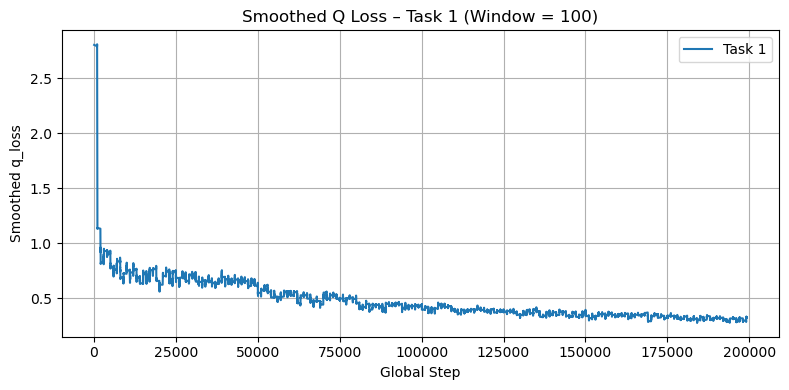

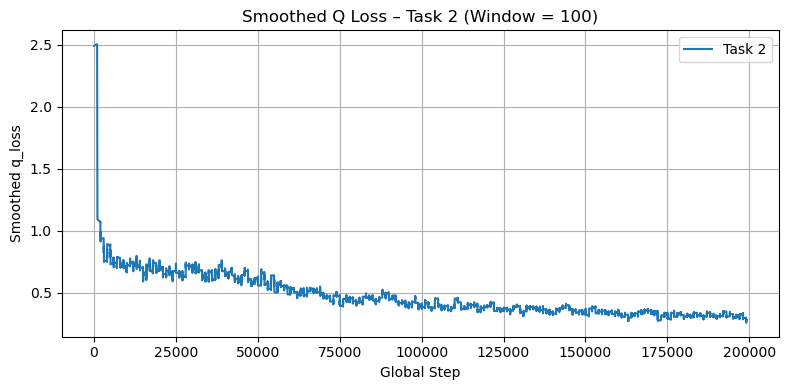

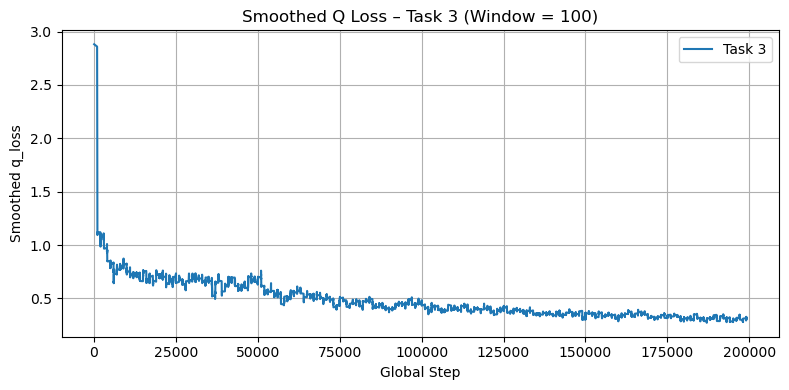

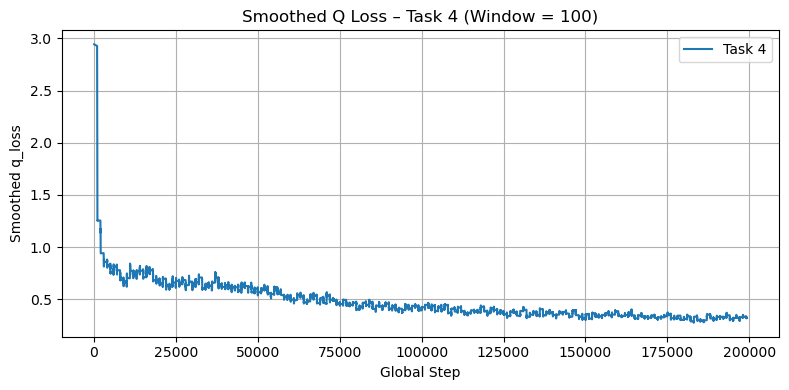

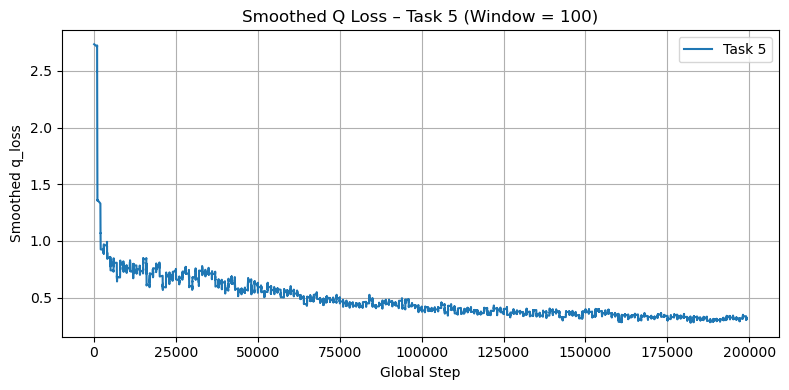

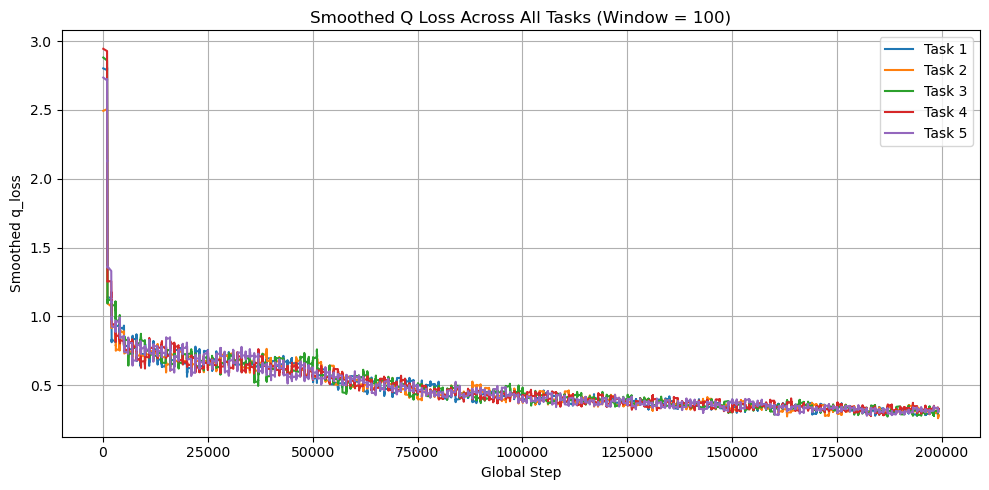

In [6]:
import re
import matplotlib.pyplot as plt
from collections import defaultdict
import numpy as np

# File path
log_file_path = "/scratch/ae2195/CASPIAN_MAML/models/models_from_local_machine/models/trained_models/aya/CASPIAN_MAML_v1_test2/loss_log.txt"
window_size = 100

# Regex to extract q_loss
q_loss_pattern = re.compile(r"Epoch (\d+) Step (\d+) Task (\d+) \| q_loss: ([\d.]+)")

# Store raw data
task_losses = defaultdict(list)
task_steps = defaultdict(list)

# Parse file
with open(log_file_path, 'r') as file:
    for line in file:
        match = q_loss_pattern.search(line)
        if match:
            epoch = int(match.group(1))
            step = int(match.group(2))
            task = int(match.group(3))
            loss = float(match.group(4))
            global_step = (epoch - 1) * 1000 + step
            task_losses[task].append(loss)
            task_steps[task].append(global_step)

# Rolling average helper
def rolling_average(values, window):
    return np.convolve(values, np.ones(window)/window, mode='valid')

# Plot per task with windowing
for task_id in range(1, 6):
    losses = task_losses[task_id]
    steps = task_steps[task_id]
    if len(losses) >= window_size:
        smoothed_losses = rolling_average(losses, window_size)
        smoothed_steps = steps[window_size - 1:]
    else:
        smoothed_losses = losses
        smoothed_steps = steps

    plt.figure(figsize=(8, 4))
    plt.plot(smoothed_steps, smoothed_losses, label=f'Task {task_id}')
    plt.title(f'Smoothed Q Loss – Task {task_id} (Window = {window_size})')
    plt.xlabel('Global Step')
    plt.ylabel('Smoothed q_loss')
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

# Combined plot
plt.figure(figsize=(10, 5))
for task_id in range(1, 6):
    losses = task_losses[task_id]
    steps = task_steps[task_id]
    if len(losses) >= window_size:
        smoothed_losses = rolling_average(losses, window_size)
        smoothed_steps = steps[window_size - 1:]
    else:
        smoothed_losses = losses
        smoothed_steps = steps

    plt.plot(smoothed_steps, smoothed_losses, label=f'Task {task_id}')

plt.title(f'Smoothed Q Loss Across All Tasks (Window = {window_size})')
plt.xlabel('Global Step')
plt.ylabel('Smoothed q_loss')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


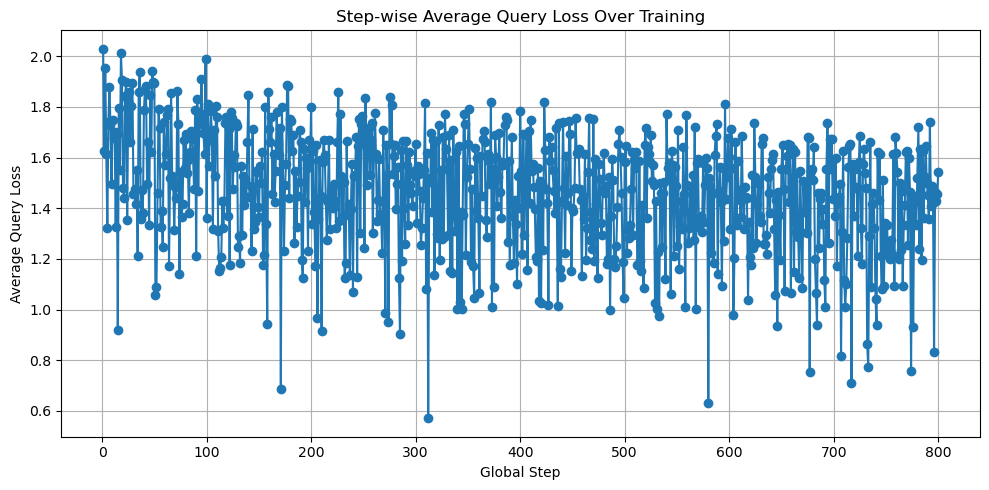

In [1]:
import matplotlib.pyplot as plt
import re
from collections import defaultdict

# Path to your log file
log_file_path = "/scratch/ae2195/CASPIAN_MAML/models/trained_models/aya/CASPIAN_MAML_v1_test1_SF_FT_train_aug/loss_log.txt"  # <-- change this to your actual file path

# Container: {(epoch, step): [loss1, loss2, ..., loss5]}
losses = defaultdict(list)

# Regex pattern to extract epoch, step, task, and loss
pattern = re.compile(r"Epoch (\d+)/\d+, Step (\d+)/\d+, Task \d+/\d+, query-loss: ([\d\.]+)")

# Parse the log file
with open(log_file_path, "r") as f:
    for line in f:
        match = pattern.search(line)
        if match:
            epoch = int(match.group(1))
            step = int(match.group(2))
            loss = float(match.group(3))
            losses[(epoch, step)].append(loss)

# Compute average loss per (epoch, step)
avg_loss = {
    (epoch, step): sum(loss_list) / len(loss_list)
    for (epoch, step), loss_list in losses.items()
}

# Prepare data for plotting
x = []
y = []

for (epoch, step) in sorted(avg_loss.keys()):
    x.append((epoch - 1) * 20 + step)  # Flatten (epoch, step) into global step number
    y.append(avg_loss[(epoch, step)])

# Plot
plt.figure(figsize=(10, 5))
plt.plot(x, y, marker='o')
plt.xlabel("Global Step")
plt.ylabel("Average Query Loss")
plt.title("Step-wise Average Query Loss Over Training")
plt.grid(True)
plt.tight_layout()
plt.show()
